# Inception-V3 Model

## Import Libraries and Set Configurations

In [1]:
# Import the relevant libraries
from utils.seed_utils import *
from utils.data_utils import *
from utils.training_evaluation_utils import *
from utils.external_validation_utils import *
from utils.cache_utils import *
from utils.results_utils import *
from utils.experiment_runner import (run_single_experiment as shared_run_single_experiment)

import os
import json
import copy
import numpy as np
import pandas as pd
import torch.optim as optim
import torch
import torch.nn as nn
from functools import partial

from sklearn.utils.class_weight import compute_class_weight
from torchvision import models
from torchvision.models import Inception_V3_Weights

import matplotlib.pyplot as plt
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
)
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from torch.utils.data import DataLoader

In [2]:
# List the configurations
DATA_DIR = "../data/EBHI-SEG"

BATCH_SIZE = 32
NUM_WORKERS = 0
IMAGE_SIZE = 299
NUM_EPOCHS_STAGE1 = 15
NUM_EPOCHS_STAGE2 = 25

LR_STAGE1 = 1e-3
LR_STAGE2 = 3e-5

WEIGHT_DECAY = 1e-4
PATIENCE = 5
LABEL_SMOOTHING = 0.05

## Multi-Run Configuration

In [3]:
# Multi-run configuration
SPLIT_SEED = 42
RUN_SEEDS = [42, 123, 2024, 3407, 9999, 7, 77, 314, 2025, 8888]
N_RUNS = len(RUN_SEEDS)
CACHE_DIR = "outputs/inceptionv3/run_cache"
RESULTS_DIR = "outputs/inceptionv3"
os.makedirs(CACHE_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)


SAVE_MODEL_PER_RUN = True
if torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
elif torch.cuda.is_available():
    DEVICE = torch.device("cuda")
else:
    DEVICE = torch.device("cpu")

print("Using device:", DEVICE)
print(f"Planned runs: {N_RUNS} (seeds {RUN_SEEDS})")

Using device: mps
Planned runs: 10 (seeds [42, 123, 2024, 3407, 9999, 7, 77, 314, 2025, 8888])


## Caching Functions

In [4]:
# Configure shared caching functions for this architecture
run_cache_path = partial(run_cache_path, cache_dir=CACHE_DIR)
run_model_path = partial(run_model_path, cache_dir=CACHE_DIR)
load_cached_run = partial(load_cached_run, cache_dir=CACHE_DIR)
save_run_cache = partial(save_run_cache, cache_dir=CACHE_DIR)

## Building the Inception-V3 Model

In [5]:
# Function to build the inceptionv3 model with the custom classifier head
def build_inceptionv3(num_classes):
    weights = Inception_V3_Weights.DEFAULT
    model = models.inception_v3(weights=weights, aux_logits=True)
    in_features = model.fc.in_features
    model.fc = nn.Sequential(
        nn.Linear(in_features, 512),
        nn.BatchNorm1d(512),
        nn.ReLU(),
        nn.Dropout(0.4),
        nn.Linear(512, 128),
        nn.BatchNorm1d(128),
        nn.ReLU(),
        nn.Dropout(0.3),
        nn.Linear(128, num_classes)
    )
    # To replace the auxiliary classifier
    if model.AuxLogits is not None:
        aux_in_features = model.AuxLogits.fc.in_features
        model.AuxLogits.fc = nn.Linear(aux_in_features, num_classes)

    return model

# Function to freeze backbone
def freeze_backbone(model):
    for param in model.parameters():
        param.requires_grad = False
    for param in model.fc.parameters():
        param.requires_grad = True
    if model.AuxLogits is not None:
        for param in model.AuxLogits.parameters():
            param.requires_grad = True

# Function to unfreeze for fine-tuning
def unfreeze_for_finetuning(model):
    for param in model.parameters():
        param.requires_grad = False
    # main classifier
    for param in model.fc.parameters():
        param.requires_grad = True
    # auxiliary classifier
    if model.AuxLogits is not None:
        for param in model.AuxLogits.parameters():
            param.requires_grad = True
    # fine-tune deeper inception blocks
    for param in model.Mixed_7a.parameters():
        param.requires_grad = True
    for param in model.Mixed_7b.parameters():
        param.requires_grad = True
    for param in model.Mixed_7c.parameters():
        param.requires_grad = True

## External Validation Configuration

In [6]:
EXTERNAL_DIR = "../data/lung_colon_image_set/Test Set"
EXTERNAL_IMAGE_SIZE = 224
EXTERNAL_BATCH_SIZE = 16
EXTERNAL_NUM_WORKERS = 0

external_class_names = [
    "Adenocarcinoma",
    "High-grade IN",
    "Low-grade IN",
    "Normal",
    "Polyp",
    "Serrated adenoma"
]
external_class_to_index = {cls: i for i, cls in enumerate(external_class_names)}

external_label_map = {
    "colon_aca": "Adenocarcinoma",
    "colon_n": "Normal"
}

external_labels = [external_class_to_index[c] for c in external_label_map.values()]
external_target_names = list(external_label_map.values())

## Single-Run Experiment

In [7]:
def run_single_experiment(run_idx, seed):
    return shared_run_single_experiment(
        run_idx=run_idx,
        seed=seed,

        # Architecture-specific configuration
        model_name="Inception-V3",
        build_model=build_inceptionv3,
        freeze_backbone=freeze_backbone,
        unfreeze_for_finetuning=unfreeze_for_finetuning,

        # Dataset and preprocessing
        data_dir=DATA_DIR,
        split_seed=SPLIT_SEED,
        image_size=IMAGE_SIZE,
        batch_size=BATCH_SIZE,
        num_workers=NUM_WORKERS,
        device=DEVICE,

        # Training configuration
        label_smoothing=LABEL_SMOOTHING,
        lr_stage1=LR_STAGE1,
        lr_stage2=LR_STAGE2,
        weight_decay=WEIGHT_DECAY,
        num_epochs_stage1=NUM_EPOCHS_STAGE1,
        num_epochs_stage2=NUM_EPOCHS_STAGE2,
        patience=PATIENCE,

        # External validation
        external_dir=EXTERNAL_DIR,
        external_label_map=external_label_map,
        external_class_to_index=external_class_to_index,
        external_image_size=EXTERNAL_IMAGE_SIZE,
        external_batch_size=EXTERNAL_BATCH_SIZE,
        external_num_workers=EXTERNAL_NUM_WORKERS,
        external_labels=external_labels,
        external_target_names=external_target_names,
        external_class_names=external_class_names,

        # Checkpoint saving
        save_model_per_run=SAVE_MODEL_PER_RUN,
        model_path_fn=run_model_path,
    )


## Run a Single Experiment (with caching)

In [8]:
# Configure the shared run-or-load function
run_or_load = partial(
    run_or_load,
    cache_dir=CACHE_DIR,
    run_single_experiment=run_single_experiment
)

## Execute All Runs

Runs (or loads from cache) each of the `N_RUNS` repetitions in sequence.

In [9]:
all_run_results = []

for i, seed in enumerate(RUN_SEEDS):
    result = run_or_load(i, seed)
    all_run_results.append(result)

print(f"\nCollected {len(all_run_results)} / {N_RUNS} runs.")

[cache] Run 0 (seed=42) already cached — skipping training.
[cache] Run 1 (seed=123) already cached — skipping training.
[cache] Run 2 (seed=2024) already cached — skipping training.
[cache] Run 3 (seed=3407) already cached — skipping training.
[cache] Run 4 (seed=9999) already cached — skipping training.
[cache] Run 5 (seed=7) already cached — skipping training.
[cache] Run 6 (seed=77) already cached — skipping training.
[cache] Run 7 (seed=314) already cached — skipping training.
[cache] Run 8 (seed=2025) already cached — skipping training.
[cache] Run 9 (seed=8888) already cached — skipping training.

Collected 10 / 10 runs.


## Aggregate Results: Mean ± SD

In [10]:
sections = {
    "Internal Test (Normal, no TTA)": "internal_normal",
    "Internal Test (TTA)": "internal_tta",
    "External Validation (Normal, no TTA)": "external_normal",
    "External Validation (TTA)": "external_tta",
}

summary_tables = {}

for title, key in sections.items():
    df = aggregate_section(all_run_results, key)
    summary_tables[key] = df

    print("\n" + "=" * 70)
    print(title, f"(n={len(all_run_results)} runs)")
    print("=" * 70)

    if df.empty:
        print("No numeric metrics found for this section.")
    else:
        print(df[["metric", "mean_pm_sd"]].to_string(index=False))


Internal Test (Normal, no TTA) (n=10 runs)
          metric      mean_pm_sd
        accuracy 0.8355 ± 0.0137
        f1_macro 0.7649 ± 0.0170
            loss 0.9815 ± 0.0293
   macro_roc_auc 0.9632 ± 0.0057
 precision_macro 0.7608 ± 0.0236
    recall_macro 0.7823 ± 0.0131
weighted_roc_auc 0.9749 ± 0.0032

Internal Test (TTA) (n=10 runs)
          metric      mean_pm_sd
        accuracy 0.8627 ± 0.0130
        f1_macro 0.7993 ± 0.0173
            loss 1.0461 ± 0.0251
   macro_roc_auc 0.9781 ± 0.0045
 precision_macro 0.7907 ± 0.0201
    recall_macro 0.8188 ± 0.0136
weighted_roc_auc 0.9827 ± 0.0025

External Validation (Normal, no TTA) (n=10 runs)
   metric      mean_pm_sd
 accuracy 0.4110 ± 0.0329
 macro_f1 0.5084 ± 0.0427
precision 0.8239 ± 0.0245
   recall 0.4110 ± 0.0329

External Validation (TTA) (n=10 runs)
   metric      mean_pm_sd
 accuracy 0.4602 ± 0.0537
 macro_f1 0.5499 ± 0.0624
precision 0.8753 ± 0.0257
   recall 0.4602 ± 0.0537


## Save Aggregated Summary and Per-Run Table
- `inceptionv3_multirun_summary.json`: mean/SD for every metric, per section
- `inceptionv3_multirun_per_run.csv`: the raw per-run scalar metrics (one row per run) for full transparency
- Each individual run's full result is also available in `outputs/inceptionv3/run_cache/`

In [11]:
# Save mean +/- SD summary
summary_json = {
    title: df.to_dict(orient="records")
    for title, df in zip(sections.keys(), summary_tables.values())
}
summary_json["n_runs"] = len(all_run_results)
summary_json["seeds"] = [r["seed"] for r in all_run_results]

summary_path = os.path.join(RESULTS_DIR, "inceptionv3_multirun_summary.json")
with open(summary_path, "w") as f:
    json.dump(summary_json, f, indent=2)
print("Saved aggregated summary to:", summary_path)

# Save a flat per-run CSV for transparency / re-analysis
per_run_rows = []
for r in all_run_results:
    row = {"run_idx": r["run_idx"], "seed": r["seed"]}
    for section_key in ["internal_normal", "internal_tta", "external_normal", "external_tta"]:
        if section_key in r:
            for k, v in flatten_numeric(r[section_key]).items():
                row[f"{section_key}.{k}"] = v
    per_run_rows.append(row)

per_run_df = pd.DataFrame(per_run_rows)
per_run_csv_path = os.path.join(RESULTS_DIR, "inceptionv3_multirun_per_run.csv")
per_run_df.to_csv(per_run_csv_path, index=False)
print("Saved per-run metrics to:", per_run_csv_path)

per_run_df

Saved aggregated summary to: outputs/inceptionv3/inceptionv3_multirun_summary.json
Saved per-run metrics to: outputs/inceptionv3/inceptionv3_multirun_per_run.csv


,run_idx,seed,internal_normal.loss,internal_normal.accuracy,internal_normal.precision_macro,internal_normal.recall_macro,internal_normal.f1_macro,internal_normal.macro_roc_auc,internal_normal.weighted_roc_auc,internal_tta.loss,...,internal_tta.macro_roc_auc,internal_tta.weighted_roc_auc,external_normal.accuracy,external_normal.precision,external_normal.recall,external_normal.macro_f1,external_tta.accuracy,external_tta.precision,external_tta.recall,external_tta.macro_f1
0,0,42,0.931702,0.838806,0.753566,0.804784,0.773217,0.974116,0.979711,1.028485,...,0.981854,0.985016,0.420,0.862666,0.420,0.500538,0.474,0.902991,0.474,0.524260
1,1,123,0.979100,0.841791,0.748666,0.775302,0.758785,0.965141,0.975168,1.032485,...,0.980461,0.983412,0.419,0.816250,0.419,0.504467,0.453,0.833263,0.453,0.532820
2,2,2024,0.988905,0.844776,0.789902,0.795555,0.783483,0.957345,0.974224,1.051352,...,0.974469,0.981965,0.465,0.857000,0.465,0.581007,0.552,0.887619,0.552,0.655954
3,3,3407,0.976185,0.826866,0.736328,0.773452,0.747362,0.965873,0.976515,1.049152,...,0.981657,0.984203,0.405,0.831710,0.405,0.483695,0.441,0.860677,0.441,0.515033
4,4,9999,0.958716,0.853731,0.792256,0.788296,0.787113,0.962680,0.976177,1.019915,...,0.979422,0.984383,0.390,0.819069,0.390,0.493905,0.433,0.879844,0.433,0.542058
5,5,7,0.982323,0.838806,0.746916,0.771763,0.754658,0.962225,0.975581,1.043094,...,0.977064,0.983020,0.416,0.825819,0.416,0.530185,0.452,0.873970,0.452,0.568355
6,6,77,0.975625,0.829851,0.769522,0.782394,0.766367,0.968066,0.976896,1.055683,...,0.981865,0.983880,0.453,0.836103,0.453,0.572328,0.548,0.886485,0.548,0.660650
7,7,314,1.047063,0.802985,0.719877,0.758851,0.731854,0.953685,0.967134,1.110299,...,0.968828,0.976209,0.370,0.794744,0.370,0.478126,0.400,0.835696,0.400,0.493084
8,8,2025,0.977325,0.835821,0.773987,0.782907,0.771018,0.963331,0.974221,1.038070,...,0.982083,0.983768,0.413,0.810465,0.413,0.500184,0.458,0.880370,0.458,0.530160
9,9,8888,0.998079,0.841791,0.777339,0.789338,0.774951,0.959614,0.973817,1.032860,...,0.973414,0.981341,0.359,0.785292,0.359,0.439712,0.391,0.911646,0.391,0.476717


## Confusion Matrix for a Single Reference Run

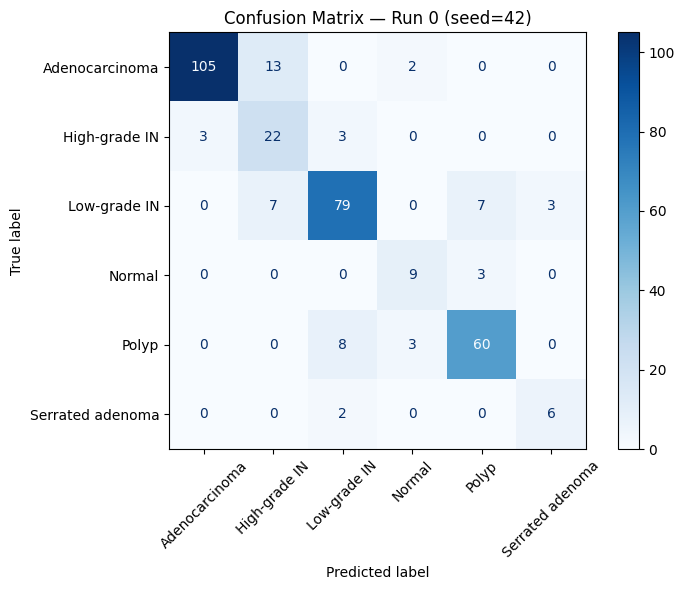

In [12]:
reference_run = all_run_results[0]

cm_ref = np.array(reference_run["internal_normal_extra"]["confusion_matrix"])
display = ConfusionMatrixDisplay(
    confusion_matrix=cm_ref,
    display_labels=reference_run["class_names"]
)
fig, ax = plt.subplots(figsize=(8, 6))
display.plot(cmap="Blues", ax=ax, values_format="d")
plt.title(f"Confusion Matrix — Run {reference_run['run_idx']} (seed={reference_run['seed']})")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()